# Activation patching in GPT-2: which attention head says "Paris"?

This notebook is the long version of the activation patching example in the TorchLens README. It
asks a narrow causal question about pretrained GPT-2 small: when the model reads
"The capital of France is", which of its 144 attention heads carries the information that makes it
predict " Paris"?

The method is activation patching. Run the model on two prompts that differ in one word, take one
internal activation from the first run, put it into the second run in place of its own value, and
see how much the output moves. A component whose patch moves the output a lot carries information
the output depends on.

Everything runs on a laptop CPU. The first run downloads GPT-2 small (about 550 MB) from the
Hugging Face Hub.

## 1. Setup: two traced runs

In [1]:
# tqdm warns at import when ipywidgets is missing.
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from transformers.utils import logging as hf_logging

import torchlens as tl

hf_logging.disable_progress_bar()
gpt2 = GPT2LMHeadModel.from_pretrained("gpt2").eval()
tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")

`tl.trace` runs the model as it is and records every operation, with each operation's output.
For Hugging Face models TorchLens tokenizes input text itself, so the prompts go in as strings.

In [3]:
france = tl.trace(gpt2, "The capital of France is")  # the run we copy activations from
italy = tl.trace(gpt2, "The capital of Italy is")  # the run we patch them into

for prompt in ("The capital of France is", "The capital of Italy is"):
    print(tokenizer.tokenize(prompt))

['The', 'Ġcapital', 'Ġof', 'ĠFrance', 'Ġis']
['The', 'Ġcapital', 'Ġof', 'ĠItaly', 'Ġis']


The two prompts tokenize to the same five tokens except at position 3 (`France` against `Italy`).
Equal lengths matter: patching copies an activation position by position, so every position in one
run has to line up with the same position in the other.

## 2. The metric: Paris minus Rome

The model's prediction for the next word is the last position of `lm_head`'s output: one score
(logit) per vocabulary entry. The metric is the score of " Paris" minus the score of " Rome". It is
positive when the model prefers Paris and negative when it prefers Rome.

In [4]:
def paris_vs_rome(trace):  # how much more the model predicts " Paris" than " Rome"
    logits = trace["lm_head"].out[0, -1]  # next-word scores
    return (logits[6342] - logits[10598]).item()  # GPT-2's token ids for " Paris" and " Rome"


print("token ids:", tokenizer.encode(" Paris"), tokenizer.encode(" Rome"))
print(f"France run: {paris_vs_rome(france):+.2f}")
print(f"Italy run:  {paris_vs_rome(italy):+.2f}")

token ids: [6342] [10598]
France run: +2.46


Italy run:  -5.25


The model knows both capitals: on the France prompt it prefers Paris, on the Italy prompt it
prefers Rome. The gap between the two numbers is the whole effect of changing the country on
this metric, and it is the yardstick for every patch below. A patch that takes the Italy run
to the France number restores this logit contrast, not necessarily the rest of the model's
output; a patch that leaves it at the Italy number did nothing.


## 3. Patch one head by hand

A selector names where in the model to intervene. `tl.module("transformer.h.9.attn")` picks the
attention module of block 9, `tl.head(8, "v")` picks the value vectors of head 8, and `&` keeps
what both pick: the values of head 8 in block 9, at every position.

`italy.fork()` makes a copy of the Italy run, so `italy` itself stays as it was. `.do(site, edit)`
applies the edit and replays the downstream operations in the recorded graph. The edit `tl.patch_from(france)`
replaces the value at the site with the value the France run recorded at the same site.

In [5]:
head_9_8 = tl.module("transformer.h.9.attn") & tl.head(8, "v")
patched = italy.fork().do(head_9_8, tl.patch_from(france))

print(f"Italy run:                      {paris_vs_rome(italy):+.2f}")
print(f"Italy run, head (9, 8) patched: {paris_vs_rome(patched):+.2f}")
print(f"France run:                     {paris_vs_rome(france):+.2f}")

Italy run:                      -5.25
Italy run, head (9, 8) patched: -0.67
France run:                     +2.46


Copying this single head's value vectors from the France run moves the Italy run a long way toward
Paris. The edited head keeps its Italy-run attention pattern and receives France-run values;
TorchLens recomputes everything downstream of the edit, so later activations can change. For this
prompt pair, then, the head carries country information to the final position, and the
prediction depends on what it carries.

For contrast, the same patch on a head in the first block barely moves the metric:


In [6]:
head_0_0 = tl.module("transformer.h.0.attn") & tl.head(0, "v")
print(
    f"head (0, 0) patched: {paris_vs_rome(italy.fork().do(head_0_0, tl.patch_from(france))):+.2f}"
)
print(f"Italy run unchanged: {paris_vs_rome(italy):+.2f}")

head (0, 0) patched: -5.24
Italy run unchanged: -5.25


## 4. Sweep all 144 heads

GPT-2 small has 12 blocks with 12 heads each. The same patch, run once per head, gives a full map.
Each patch starts from a fresh fork of the Italy run, so the patches do not accumulate.

In [7]:
heads = {
    (b, h): tl.module(f"transformer.h.{b}.attn") & tl.head(h, "v")
    for b in range(12)
    for h in range(12)
}  # values of all 144 attention heads

start = time.perf_counter()
effects = {
    bh: paris_vs_rome(italy.fork().do(head, tl.patch_from(france))) for bh, head in heads.items()
}  # patch each head from France into Italy
print(f"{len(effects)} patched runs in {time.perf_counter() - start:.0f} s")
max(effects, key=effects.get)  # the head that matters most

144 patched runs in 51 s


(9, 8)

The heatmap shows each head's effect as the change it makes to the metric, the patched Italy run
minus the unpatched one. Red heads push the Italy run toward Paris; blue heads push it toward Rome.

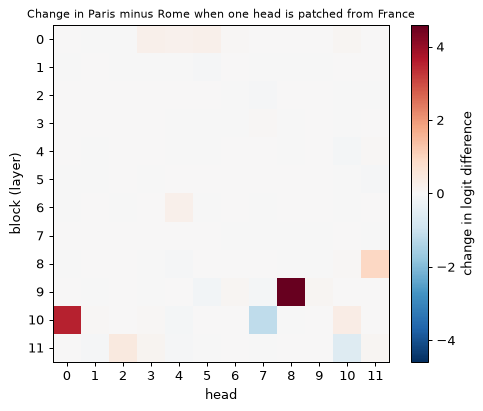

In [8]:
baseline = paris_vs_rome(italy)
grid = np.array([[effects[b, h] - baseline for h in range(12)] for b in range(12)])
limit = np.abs(grid).max()

fig, ax = plt.subplots(figsize=(5.6, 4.6), dpi=90)
image = ax.imshow(grid, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set_xticks(range(12))
ax.set_yticks(range(12))
ax.set_xlabel("head")
ax.set_ylabel("block (layer)")
ax.set_title("Change in Paris minus Rome when one head is patched from France")
ax.title.set_fontsize(9)
fig.colorbar(image, ax=ax, label="change in logit difference")
fig.tight_layout()
plt.show()

In [9]:
gap = paris_vs_rome(france) - baseline
ranked = sorted(effects, key=lambda bh: effects[bh] - baseline, reverse=True)
print(f"France minus Italy gap: {gap:.2f}")
print("head      change   share of gap")
for b, h in ranked[:8]:
    change = effects[b, h] - baseline
    print(f"({b:2d}, {h:2d})  {change:+7.2f}   {change / gap:6.0%}")

France minus Italy gap: 7.71
head      change   share of gap
( 9,  8)    +4.58      59%
(10,  0)    +3.54      46%
( 8, 11)    +0.94      12%
(11,  2)    +0.46       6%
(10, 10)    +0.34       4%
( 6,  4)    +0.24       3%
( 0,  5)    +0.23       3%
( 0,  3)    +0.22       3%


For this prompt pair and this value-patching experiment, the largest effects sit in a few heads
of the later blocks, and most heads do next to nothing. A small effect does not show that a head
carries no country information.

Single-head effects need not add up, because heads can interact. The next step checks that
directly.


## 5. Patch two heads together

`|` combines two selectors into one site that covers both. This is the README's last line: patch
heads (9, 8) and (10, 0) from France into a copy of the Italy run.

In [10]:
both = italy.fork().do(heads[9, 8] | heads[10, 0], tl.patch_from(france))
paris_vs_rome(italy), paris_vs_rome(both)  # the model now prefers Paris over Rome

(-5.252708435058594, 2.9891281127929688)

In [11]:
single_sum = (effects[9, 8] - baseline) + (effects[10, 0] - baseline)
print(f"sum of the two single-head changes: {single_sum:+.2f}")
print(f"change with both patched together:  {paris_vs_rome(both) - baseline:+.2f}")

sum of the two single-head changes: +8.12
change with both patched together:  +8.24


Patching these two heads out of 144, at their value vectors only, makes Paris score above Rome in
the Italy run. For this prompt pair and metric, the joint change (+8.24) is close to the sum of
the two single changes (+8.12).


## 6. What activation patching shows, and its pitfalls

**What it shows.** A patch is an intervention, not a correlation: if copying a head's values from
the France run changes the Italy run's answer, the answer depends on what that head carries, for
this prompt pair, this site and this metric.

**Which run is clean and which is corrupt.** This notebook copies France activations into the
Italy run and asks which heads restore Paris. Patching the other way, copying Italy into France,
asks which heads disturb Paris, and can give different heads. Both directions are conditional on
the prompt pair, the patched site and the metric; neither alone shows that a head is necessary or
sufficient in general.

**The pair of prompts.** One France and Italy pair is one data point. The heads found here may
encode "France" specifically, or capital cities in general, or something about this sentence
frame. Averaging the effects over many pairs (other countries, other templates) and checking that
the top heads stay on top is what turns a single heatmap into a finding.

**The metric.** The Paris minus Rome logit difference measures the one contrast this question is
about. A probability saturates (once Paris is at 0.9, a large internal change barely moves it),
and a metric over the whole vocabulary can be dominated by tokens nobody cares about.

**The site.** Patching a head's values is one choice among several. Patching its output (after
attention mixes the values) or its queries and keys asks different questions; `tl.head(h, "q")`
and `tl.head(h, "k")` name those facets. Patching at every position, as here, also hides where the
information sits: restricting the patch to one position (`tl.patch_from(france, positions=...)`)
separates the country token from the final token.
